# Figure 2 | Conditional acquisition prediction and task-dependent pretraining benefits

In [1]:
import json
import re
import textwrap
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

SMALL = 6.0  # minimum annotation size anywhere in the figures

mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7.5,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.dpi": 400,
    "figure.dpi": 140,
})
print("matplotlib", mpl.__version__)

matplotlib 3.9.2


## 1. Configuration — which run directory backs which panel

In [2]:
# evostate paths: data in data/manuscript, analysis code in notebooks/manuscript/lib,
# figures written to results/rendered/manuscript.
REPO = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'data/manuscript').is_dir() and (p / 'notebooks/manuscript/lib').is_dir()), None)
if REPO is None:
    raise FileNotFoundError('Start Jupyter inside the evostate repository.')
MANUSCRIPT_DATA = REPO / 'data/manuscript'
MANUSCRIPT_LIB = REPO / 'notebooks/manuscript/lib'
RENDERED = REPO / 'results/rendered/manuscript'
BASE = MANUSCRIPT_DATA / "results_repr_evo"
OUT = RENDERED / "figure2"
OUT.mkdir(parents=True, exist_ok=True)

HT_SUFFIX = "grouped_ts_contrastive_identity_state_ht_second-order_r100_timeout1800"

TASKS = [
    dict(dataset="M. tuberculosis", task="Genes19",
         run=BASE / "tuberculosis_genes19" / "hypertraps_vs_two_stage" / f"genes19_{HT_SUFFIX}"),
    dict(dataset="M. tuberculosis", task="Antibiotics10",
         run=BASE / "tuberculosis_antibiotics10" / "hypertraps_vs_two_stage" / f"antibiotics10_{HT_SUFFIX}"),
    # `cost_run` overrides where wall clock is read from, and only that. These two runs predate
    # the evaluator that writes method_runtime.csv, so their timings come from the 2026-09-09
    # grouped_cv re-run of the same task; every metric below still comes from `run`.
    dict(dataset="M. tuberculosis", task="Combined29",
         run=BASE / "tuberculosis_combined29" / "hypertraps_vs_two_stage" / f"combined29_{HT_SUFFIX}",
         cost_run=BASE / "tuberculosis_combined29" / "grouped_cv" / "eval"),
    dict(dataset="K. pneumoniae", task="Kleborate22",
         run=BASE / "microreact_kp_kleborate22" / "hypertraps_vs_two_stage" / f"kleborate_{HT_SUFFIX}",
         cost_run=BASE / "microreact_kp_kleborate22" / "grouped_cv" / "eval"),
    dict(dataset="E. coli", task="MEC",
         run=BASE / "ecoli2026_route_b" / "endpoint" / "two_stage_temporal_inferred" / "MEC" / "eval"),
    dict(dataset="E. coli", task="NIT",
         run=BASE / "ecoli2026_route_b" / "endpoint" / "two_stage_temporal_inferred" / "NIT" / "eval"),
    dict(dataset="E. coli", task="TMP",
         run=BASE / "ecoli2026_route_b" / "endpoint" / "two_stage_temporal_inferred" / "TMP" / "eval"),
]

DATASETS = ["M. tuberculosis", "K. pneumoniae", "E. coli"]

METHODS = [
    ("B0_uniform", "Uniform", "#e8e8e8"),
    ("B1_prevalence", "Prevalence", "#8a8a8a"),
    ("TS_random_init", "No pretraining", "#7fb2da"),
    ("TS_pretrained", "EvoState", "#17466f"),
    ("HT", "HyperTraPS", "#e08214"),
]
METHOD_KEYS = [m[0] for m in METHODS]

METRICS = [("mean_logl", "logL", False), ("top1", "Top-1", True), ("top3", "Top-3", True),
           ("top5", "Top-5", True), ("mrr", "MRR", True), ("auc", "AUC", True)]
TOPK = [("top1", 1), ("top3", 3), ("top5", 5)]
# bounded metrics shown in Fig. 2j-l: (key, label, fill colour) on a four-step blue ramp
DELTA_METRICS = [("top1", "Top-1", "#dce8f4"), ("top5", "Top-5", "#9dc3e0"),
                 ("mrr", "MRR", "#4a7fb0"), ("auc", "AUC", "#17466f")]

for t in TASKS:
    t.setdefault("cost_run", t["run"])  # timings default to the run the metrics come from
    for k in ("run", "cost_run"):
        assert (t[k] / "eval_summary.json").exists(), f"missing eval_summary: {t[k]}"
split = [t["task"] for t in TASKS if t["cost_run"] != t["run"]]
print("all 7 run directories resolved; output ->", OUT)
print("timing read from a separate run for:", split or "none")

all 7 run directories resolved; output -> /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure2
timing read from a separate run for: ['Combined29', 'Kleborate22']


## 2. Parse the evaluation artefacts (metrics, timings, HyperTraPS feasibility)

In [3]:
def load_json(path):
    with open(path) as fh:
        return json.load(fh)


def resolve_method(available, canonical):
    """Map a canonical method key onto the key actually present in a run.

    HyperTraPS is stored with a variant suffix (e.g. ``HT_second-order``) and is absent
    altogether in runs where the sampler never completed.
    """
    if canonical in available:
        return canonical
    if canonical == "HT":
        hits = [k for k in available if k.startswith("HT")]
        return hits[0] if hits else None
    return None


def read_runtime(run, summary):
    """Wall clock per method. Some runs store it in eval_summary, others in method_runtime.csv."""
    rt = summary.get("method_runtime_sec") or {}
    if rt:
        return rt, "eval_summary.json"
    csv_path = run / "method_runtime.csv"
    if csv_path.exists():
        tbl = pd.read_csv(csv_path)
        rt = {r["method"]: {k: (None if pd.isna(r[k]) else float(r[k]))
                            for k in ("n_folds", "mean_train_sec", "mean_eval_sec", "mean_total_sec")}
              for _, r in tbl.iterrows()}
        return rt, "method_runtime.csv"
    return {}, None


def read_ht_log(run):
    """Count HyperTraPS fold failures and recover the configured timeout from run.log."""
    info = dict(ht_timeout_sec=np.nan, ht_folds_timed_out=0, ht_folds_failed_other=0,
                ht_log_found=False)
    log = run / "run.log"
    if not log.exists():
        return info
    info["ht_log_found"] = True
    txt = log.read_text(errors="ignore")
    m = re.search(r"ht_timeout\s*:\s*([0-9.]+)", txt)
    if m:
        info["ht_timeout_sec"] = float(m.group(1))
    fails = re.findall(r"HyperTraPS fold (\d+) failed: ([^\n]*)", txt)
    info["ht_folds_timed_out"] = len({f for f, msg in fails if "Timeout" in msg})
    info["ht_folds_failed_other"] = len({f for f, msg in fails if "Timeout" not in msg})
    return info


def bh_fdr(pvals):
    """Benjamini-Hochberg adjusted p values, ignoring non-finite entries."""
    p = np.asarray(pvals, dtype=float)
    q = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    m = int(ok.sum())
    if m == 0:
        return q
    vals = p[ok]
    order = np.argsort(vals)
    adj = vals[order] * m / np.arange(1, m + 1)
    adj = np.minimum.accumulate(adj[::-1])[::-1]
    out = np.empty(m)
    out[order] = np.clip(adj, 0, 1)
    q[ok] = out
    return q


rows_method, rows_fold, rows_task = [], [], []

for t in TASKS:
    summary = load_json(t["run"] / "eval_summary.json")
    overall = summary["overall"]
    cost_summary = (summary if t["cost_run"] == t["run"]
                    else load_json(t["cost_run"] / "eval_summary.json"))
    runtime, runtime_source = read_runtime(t["cost_run"], cost_summary)
    runtime_run = str(t["cost_run"].relative_to(BASE))
    htlog = read_ht_log(t["run"])

    fm_path = t["run"] / "fold_metrics.json"
    folds = load_json(fm_path)["folds"] if fm_path.exists() else summary.get("folds", [])
    n_folds = summary.get("n_folds") or len(folds)
    base_logl = overall["B0_uniform"]["mean_logl"]

    ht_real = resolve_method(overall, "HT")
    if ht_real:
        ht_status, ht_note = None, None
    elif htlog["ht_folds_timed_out"]:
        ht_status = "timed out"
        ht_note = (f"HyperTraPS:\n{htlog['ht_folds_timed_out']}/{n_folds} folds\n> "
                   f"{htlog['ht_timeout_sec']:,.0f} s" if np.isfinite(htlog["ht_timeout_sec"])
                   else f"HyperTraPS:\n{htlog['ht_folds_timed_out']}/{n_folds} folds\ntimed out")
    elif (summary.get("ht_runtime") or {}).get("enabled"):
        ht_status, ht_note = "failed", "HyperTraPS:\nsampler failed"
    else:
        ht_status, ht_note = "not attempted", "HyperTraPS:\nnot attempted"

    for key, label, _ in METHODS:
        real = resolve_method(overall, key)
        if real is None:
            rows_method.append(dict(dataset=t["dataset"], task=t["task"], method=key,
                                    method_label=label, available=False))
            continue
        rec = overall[real]
        per_fold = [f["methods"][real]["mean_logl"] - f["methods"]["B0_uniform"]["mean_logl"]
                    for f in folds if real in f["methods"]]
        rt = runtime.get(real, {}) or {}
        row = dict(
            dataset=t["dataset"], task=t["task"], method=key, method_label=label, available=True,
            lift_vs_uniform=rec["mean_logl"] - base_logl,
            lift_sem=float(np.std(per_fold, ddof=1) / np.sqrt(len(per_fold))) if len(per_fold) > 1 else np.nan,
            auc_all=rec.get("auc_all"), event_mrr=rec.get("event_mrr"), rec3=rec.get("rec3"),
            rec5=rec.get("rec5"), multi_top1=rec.get("multi_top1"),
            mean_total_sec=rt.get("mean_total_sec"), mean_train_sec=rt.get("mean_train_sec"),
            runtime_source=runtime_source, runtime_run=runtime_run,
        )
        for mkey, _, _ in METRICS:
            row[mkey] = rec.get(mkey)
            vals = [f["methods"][real].get(mkey) for f in folds if real in f["methods"]]
            vals = [v for v in vals if v is not None]
            row[f"{mkey}_sem"] = (float(np.std(vals, ddof=1) / np.sqrt(len(vals)))
                                  if len(vals) > 1 else np.nan)
        rows_method.append(row)

    for f in folds:
        mm = f["methods"]
        if "TS_pretrained" in mm and "TS_random_init" in mm:
            rec = dict(dataset=t["dataset"], task=t["task"], fold=f.get("fold"))
            for mkey, _, _ in METRICS:
                a, b = mm["TS_pretrained"].get(mkey), mm["TS_random_init"].get(mkey)
                rec[f"delta_{mkey}"] = (a - b) if (a is not None and b is not None) else np.nan
            rows_fold.append(rec)

    def cmp(name):
        c = summary.get(name) or {}
        return c.get("delta_mean_logl", np.nan), c.get("p_value", np.nan)

    d_rand, p_rand = cmp("pretrained_vs_random")
    d_prev, p_prev = cmp("pretrained_vs_prevalence")
    d_ht, p_ht = cmp("pretrained_vs_hypertraps")

    mean_cand = overall["B0_uniform"].get("mean_n_candidates")
    if mean_cand is None:
        cand = [f["methods"]["B0_uniform"].get("mean_n_candidates") for f in folds]
        cand = [c for c in cand if c is not None]
        mean_cand = float(np.mean(cand)) if cand else np.nan
    cand_inferred = not np.isfinite(mean_cand)
    if cand_inferred:
        mean_cand = float(np.exp(-base_logl))  # uniform ranker over |C| has logL = -log|C|

    ts_rt = (runtime.get("TS_pretrained") or {}).get("mean_total_sec")
    stage1_rt = (runtime.get("TS_pretrained_stage1") or {}).get("mean_train_sec")
    rnd_rt = (runtime.get("TS_random_init") or {}).get("mean_total_sec")
    ht_runtime, _ = read_runtime(t["run"], summary)  # HyperTraPS always from its own run
    ht_rt = (ht_runtime.get(ht_real) or {}).get("mean_total_sec") if ht_real else None
    prof = summary.get("transition_profile", {})
    n_multi = prof.get("multi_gain")
    n_eval = prof.get("n_eval_transitions") or summary.get("n_transitions")

    rows_task.append(dict(
        dataset=t["dataset"], task=t["task"], run=str(t["run"].relative_to(BASE)),
        L=summary.get("L"), n_transitions=summary.get("n_transitions"),
        n_groups=summary.get("n_groups"), n_folds=n_folds,
        mean_n_candidates=mean_cand, mean_n_candidates_inferred=cand_inferred,
        frac_multi_gain=(n_multi / n_eval) if (n_multi is not None and n_eval) else np.nan,
        delta_vs_random=d_rand, p_vs_random=p_rand,
        delta_vs_prevalence=d_prev, p_vs_prevalence=p_prev,
        delta_vs_hypertraps=d_ht, p_vs_hypertraps=p_ht,
        sec_per_fold_evostate=ts_rt, sec_per_fold_random_init=rnd_rt, sec_per_fold_hypertraps=ht_rt,
        sec_per_fold_pretrain_stage1=stage1_rt,
        sec_per_fold_evostate_total=((ts_rt + stage1_rt) if (ts_rt and stage1_rt) else ts_rt),
        evostate_total_includes_stage1=bool(stage1_rt),
        speedup_vs_hypertraps=(ht_rt / (ts_rt + (stage1_rt or 0.0)))
                              if (ht_rt and ts_rt) else np.nan,
        finetune_speedup=(rnd_rt / ts_rt) if (rnd_rt and ts_rt) else np.nan,
        runtime_source=runtime_source, runtime_run=runtime_run,
        runtime_from_other_run=(t["cost_run"] != t["run"]),
        ht_status=ht_status, ht_note=ht_note,
        ht_timeout_sec=htlog["ht_timeout_sec"], ht_folds_timed_out=htlog["ht_folds_timed_out"],
    ))

df_method = pd.DataFrame(rows_method)
df_fold = pd.DataFrame(rows_fold)
df_task = pd.DataFrame(rows_task)

for col in ["p_vs_random", "p_vs_prevalence", "p_vs_hypertraps"]:
    df_task[col.replace("p_", "q_")] = bh_fdr(df_task[col].values)

legacy_cols = [c for c in df_task if c.startswith(('p_vs_', 'q_vs_'))]
legacy_tests = df_task[['dataset', 'task'] + legacy_cols].copy()
legacy_tests['status'] = 'historical; resampling resolution/dependence not audited; not used for significance'
legacy_tests.to_csv(OUT / 'historical_tests_audit.csv', index=False)
df_task[legacy_cols] = np.nan
df_task[["dataset", "task", "L", "n_transitions", "n_groups", "delta_vs_random", "p_vs_random",
         "q_vs_random", "ht_status", "runtime_source"]]

,dataset,task,L,n_transitions,n_groups,delta_vs_random,p_vs_random,q_vs_random,ht_status,runtime_source
0,M. tuberculosis,Genes19,19,264,44,-0.006810,NaN,NaN,None,eval_summary.json
1,M. tuberculosis,Antibiotics10,10,427,58,-0.000276,NaN,NaN,None,eval_summary.json
2,M. tuberculosis,Combined29,29,485,58,0.008801,NaN,NaN,timed out,eval_summary.json
3,K. pneumoniae,Kleborate22,22,9026,980,0.014698,NaN,NaN,timed out,eval_summary.json
4,E. coli,MEC,858,2258,33,2.742250,NaN,NaN,not attempted,eval_summary.json
5,E. coli,NIT,320,1819,36,1.118825,NaN,NaN,not attempted,eval_summary.json
6,E. coli,TMP,1081,4154,38,2.517841,NaN,NaN,not attempted,eval_summary.json


In [4]:
# Pretraining contrast per task: aggregate delta per metric, fold-level mean, CI and sign consistency
piv = (df_method[df_method["available"]]
       .pivot_table(index=["dataset", "task"], columns="method", values=[m[0] for m in METRICS]))

rows = []
for (ds, task), r in piv.iterrows():
    rec = dict(dataset=ds, task=task)
    for mkey, _, _ in METRICS:
        rec[f"{mkey}_pre"] = r[(mkey, "TS_pretrained")]
        rec[f"{mkey}_rnd"] = r[(mkey, "TS_random_init")]
        rec[f"delta_{mkey}"] = r[(mkey, "TS_pretrained")] - r[(mkey, "TS_random_init")]
    fs = df_fold.query("dataset == @ds and task == @task")
    for mkey, _, _ in METRICS:
        v = fs[f"delta_{mkey}"].astype(float)
        rec[f"fold_mean_{mkey}"] = v.mean()
        rec[f"fold_ci95_{mkey}"] = 2.776 * v.std(ddof=1) / np.sqrt(v.notna().sum())  # t_{.975, df=4}
        rec[f"n_folds_positive_{mkey}"] = int((v > 0).sum())
        lo = rec[f"fold_mean_{mkey}"] - rec[f"fold_ci95_{mkey}"]
        hi = rec[f"fold_mean_{mkey}"] + rec[f"fold_ci95_{mkey}"]
        rec[f"ci_excludes_zero_{mkey}"] = bool(np.isfinite(lo) and np.isfinite(hi) and lo * hi > 0)
    rec["n_folds"] = int(len(fs))
    rows.append(rec)

df_delta = (pd.DataFrame(rows)
            .merge(df_task[["dataset", "task", "L", "mean_n_candidates", "delta_vs_random",
                            "p_vs_random", "q_vs_random", "finetune_speedup",
                            "speedup_vs_hypertraps"]], on=["dataset", "task"], how="left"))

df_method.to_csv(OUT / "figure2_source_data_methods.csv", index=False)
df_fold.to_csv(OUT / "figure2_source_data_folds.csv", index=False)
df_task.to_csv(OUT / "figure2_source_data_tasks.csv", index=False)
df_delta.to_csv(OUT / "figure2_source_data_pretraining_delta.csv", index=False)
df_delta[["dataset", "task", "delta_mean_logl", "q_vs_random", "delta_top1", "ci_excludes_zero_top1",
          "delta_top5", "ci_excludes_zero_top5", "delta_mrr", "ci_excludes_zero_mrr",
          "delta_auc", "ci_excludes_zero_auc"]].round(4)

,dataset,task,delta_mean_logl,q_vs_random,delta_top1,ci_excludes_zero_top1,delta_top5,ci_excludes_zero_top5,delta_mrr,ci_excludes_zero_mrr,delta_auc,ci_excludes_zero_auc
0,E. coli,MEC,2.7410,NaN,0.2736,True,0.5725,True,0.3856,True,0.1869,True
1,E. coli,NIT,1.1173,NaN,0.1283,False,0.1202,True,0.1224,True,0.0397,True
2,E. coli,TMP,2.5182,NaN,0.3441,True,0.5408,True,0.4204,True,0.1870,True
3,K. pneumoniae,Kleborate22,0.0146,NaN,-0.0032,False,0.0108,True,0.0007,False,0.0017,False
4,M. tuberculosis,Antibiotics10,-0.0006,NaN,-0.0218,False,0.0051,False,-0.0070,False,0.0010,False
5,M. tuberculosis,Combined29,0.0250,NaN,-0.0143,False,0.0090,False,0.0023,False,0.0061,False
6,M. tuberculosis,Genes19,-0.0082,NaN,0.0063,False,-0.0038,False,0.0026,False,-0.0039,False


## 3. Shared plotting helpers

In [5]:
COLOR = {k: c for k, _, c in METHODS}
LABEL = {k: l for k, l, _ in METHODS}
DARK = "#17466f"
ORANGE = "#b35806"


def stars(p):
    return ''

def fmt_q(q):
    return ''


def tasks_of(dataset):
    return [t["task"] for t in TASKS if t["dataset"] == dataset]


def italic_title(dataset):
    genus, species = dataset.split()
    return f"$\\it{{{genus}}}$ $\\it{{{species}}}$"


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(length=2.4, pad=1.6)


def panel_letter(ax, letter, dx=-28, dy=6):
    ax.annotate(letter, xy=(0, 1), xycoords="axes fraction", xytext=(dx, dy),
                textcoords="offset points", ha="left", va="bottom",
                fontsize=9, fontweight="bold")


def task_label(dataset, task, mode="n"):
    st = df_task.query("dataset == @dataset and task == @task").iloc[0]
    if mode == "n":
        return (f"{task}\n$L$={int(st['L'])}\n$n$={int(st['n_transitions']):,}"
                f"/{int(st['n_groups'])}")
    rel = "$\\approx$" if st["mean_n_candidates_inferred"] else "="
    return "{}\n$|\\mathcal{{C}}|${}{:.0f}".format(task, rel, st["mean_n_candidates"])


def task_ticks(ax, dataset, mode="n"):
    tks = tasks_of(dataset)
    ax.set_xticks(range(len(tks)))
    ax.set_xticklabels([task_label(dataset, t, mode) for t in tks])
    ax.set_xlim(-0.5, len(tks) - 0.5)


def grouped_x(i, j, n_m, width):
    return i + (j - (n_m - 1) / 2) * width


def build_ht_note(dataset):
    """One orange annotation per panel: why HyperTraPS has no bar.

    The comparison itself is drawn as an orange bracket in the panel, so the text carries
    only the reason a bar is missing.
    """
    reasons = {}
    for t in tasks_of(dataset):
        st = df_task.query("dataset == @dataset and task == @t").iloc[0]
        if np.isfinite(st["q_vs_hypertraps"]):
            continue  # comparison possible -> shown as a bracket, not as text
        if st["ht_status"] == "timed out":
            key = (f"{int(st['ht_folds_timed_out'])}/{int(st['n_folds'])} folds\n"
                   f"> {st['ht_timeout_sec']:,.0f} s")
        else:
            key = st["ht_status"] or "no estimate"
        reasons.setdefault(key, []).append(t)
    return "\n".join(f"HyperTraPS:\n{k}" for k in reasons)


def sig_bracket(ax, xa, xb, ytop, label, color, span):
    """A significance bracket with a compact star/n.s. label."""
    if not label:
        return
    ax.plot([xa, xa, xb, xb], [ytop, ytop + span * 0.020, ytop + span * 0.020, ytop],
            lw=0.5, color=color, clip_on=False)
    ax.text((xa + xb) / 2, ytop + span * 0.030, label, ha="center", va="bottom",
            fontsize=SMALL + 0.8, color=color, clip_on=False)


def method_legend(fig, y=0.985, ncol=5):
    handles = [Patch(facecolor=COLOR[k], edgecolor="#777777", linewidth=0.3, label=LABEL[k])
               for k in METHOD_KEYS]
    fig.legend(handles=handles, ncol=ncol, frameon=False, loc="upper center",
               bbox_to_anchor=(0.5, y), columnspacing=1.3, handlelength=1.2,
               handletextpad=0.45, fontsize=7)


print("helpers ready")

helpers ready


## 4. Figure 2 (main text): a–c log-likelihood, d–f Top-$k$, g–i $\Delta$logL, j–l $\Delta$metric


Figure 2 written (a-c logL | d-f Top-k | g-i dlogL | j-l dmetric)


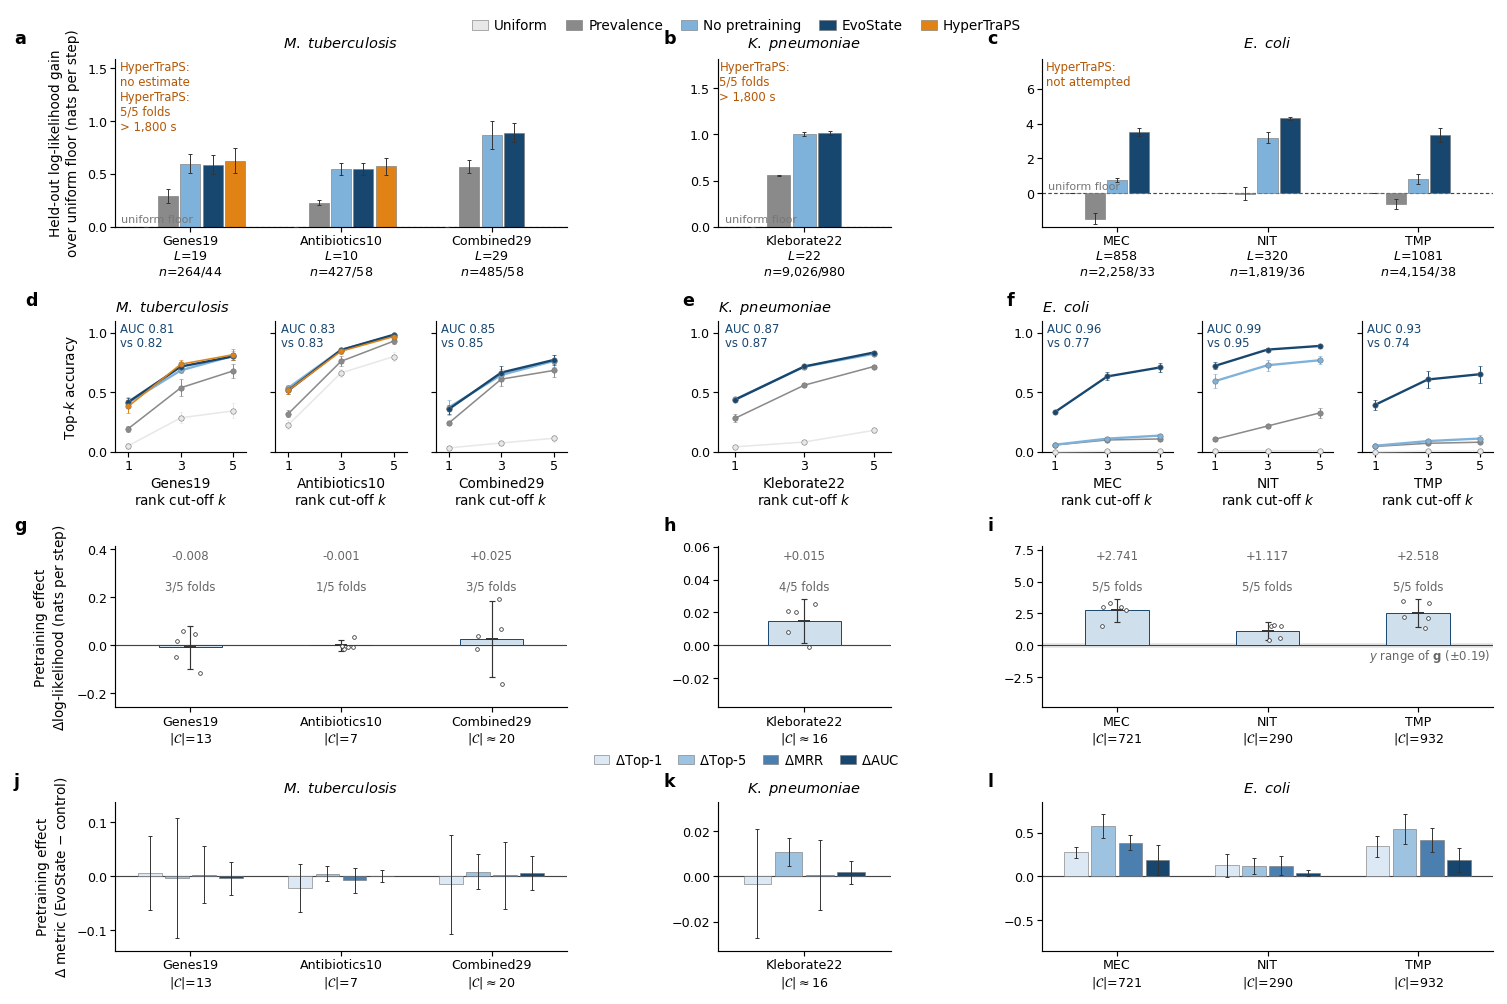

In [6]:
def draw_topk(axes, dataset, letter, show_ylabel, letter_dx=-28):
    """Row 2 (d-f): Top-k accuracy curves (k = 1, 3, 5), one small panel per task."""
    ks = [k for _, k in TOPK]
    for ai, (ax, task) in enumerate(zip(axes, tasks_of(dataset))):
        sub = df_method.query("dataset == @dataset and task == @task")
        for key in METHOD_KEYS:
            r = sub.query("method == @key").iloc[0]
            if not r["available"]:
                continue
            ys = [float(r[m]) for m, _ in TOPK]
            errs = [float(r[f"{m}_sem"]) for m, _ in TOPK]
            lw = 1.2 if key in ("TS_pretrained", "TS_random_init") else 0.8
            ax.errorbar(ks, ys, yerr=errs, color=COLOR[key], lw=lw, marker="o", ms=2.8,
                        mfc=COLOR[key], mec="#777777", mew=0.3, elinewidth=0.5, capsize=1.0,
                        capthick=0.5, zorder=3, clip_on=False)
        pre = sub.query("method == 'TS_pretrained'").iloc[0]
        rnd = sub.query("method == 'TS_random_init'").iloc[0]
        ax.set_ylim(0, 1.10)
        ax.set_yticks([0, 0.5, 1.0])
        ax.set_xlim(0.5, 5.5)
        ax.set_xticks(ks)
        ax.set_xlabel(f"{task}\nrank cut-off $k$", labelpad=2)
        ax.text(0.04, 0.99, f"AUC {pre['auc']:.2f}\nvs {rnd['auc']:.2f}", transform=ax.transAxes,
                ha="left", va="top", fontsize=SMALL, color=DARK, linespacing=1.15)
        style(ax)
        if ai == 0:
            if show_ylabel:
                ax.set_ylabel("Top-$k$ accuracy")
            panel_letter(ax, letter, dx=letter_dx)
            ax.set_title(italic_title(dataset), pad=5, loc="left")
        else:
            ax.set_yticklabels([])


def draw_effect(ax, dataset, letter, show_ylabel, ref_span=None, ref_letter="g",
                letter_dx=-28):
    """Row 3 (g-i): ΔlogL with individual folds and 95% CI."""
    tks = tasks_of(dataset)
    rng = np.random.default_rng(0)
    sub_d = df_delta[df_delta["dataset"] == dataset]
    sub_f = df_fold[df_fold["dataset"] == dataset]

    reach = np.concatenate([
        sub_f["delta_mean_logl"].astype(float).values,
        (sub_d["fold_mean_mean_logl"] + sub_d["fold_ci95_mean_logl"]).astype(float).values,
        (sub_d["fold_mean_mean_logl"] - sub_d["fold_ci95_mean_logl"]).astype(float).values,
        sub_d["delta_mean_logl"].astype(float).values])
    hi = max(1e-3, float(np.nanmax(np.abs(reach))))
    ax.set_ylim(-hi * 1.35, hi * 2.15)

    if ref_span is not None and ref_span < hi:
        ax.axhspan(-ref_span, ref_span, color="#bbbbbb", alpha=0.30, lw=0, zorder=0)
        ax.text(len(tks) - 0.52, -ref_span, f"$y$ range of $\\bf{{{ref_letter}}}$ ($\\pm${ref_span:.2f})",
                ha="right", va="top", fontsize=SMALL, color="#666666")

    for i, task in enumerate(tks):
        d = sub_d.query("task == @task").iloc[0]
        sig = np.isfinite(d["q_vs_random"]) and d["q_vs_random"] < 0.05
        ax.bar(i, d["delta_mean_logl"], width=0.42, color=DARK if sig else "#cfdfeb",
               edgecolor=DARK, linewidth=0.5, zorder=2)
        ax.errorbar(i, d["fold_mean_mean_logl"], yerr=d["fold_ci95_mean_logl"], fmt="_", ms=6,
                    mec="#333333", ecolor="#333333", elinewidth=0.6, capsize=1.5, capthick=0.6,
                    zorder=3)
        pf = sub_f.query("task == @task")["delta_mean_logl"].astype(float).values
        ax.scatter(i + rng.uniform(-0.10, 0.10, size=len(pf)), pf, s=3.6, facecolor="white",
                   edgecolor="#333333", linewidth=0.4, zorder=4, clip_on=False)
        ax.text(i, hi * 2.08,
                f"{d['delta_mean_logl']:+.3f}\n{fmt_q(d['q_vs_random'])}\n"
                f"{int(d['n_folds_positive_mean_logl'])}/{int(d['n_folds'])} folds",
                ha="center", va="top", fontsize=SMALL, linespacing=1.25,
                color=DARK if sig else "#666666")

    ax.axhline(0, color="#444444", lw=0.6, zorder=1)
    task_ticks(ax, dataset, "cand")
    if show_ylabel:
        ax.set_ylabel("Pretraining effect\n$\\Delta$log-likelihood (nats per step)")
    style(ax)
    panel_letter(ax, letter, dx=letter_dx)
    return hi


def draw_logl(ax, dataset, letter, show_ylabel, letter_dx=-28):
    """Row 1 (a-c): logL gain over the uniform floor, with both contrasts as brackets."""
    tks, n_m = tasks_of(dataset), len(METHOD_KEYS)
    width = 0.74 / n_m
    sub = df_method[df_method["dataset"] == dataset]
    ht_notes = build_ht_note(dataset)
    lifts = sub["lift_vs_uniform"].astype(float)
    ymax = max(0.3, float(np.nanmax(lifts)) * 1.78)
    ymin = min(0.0, float(np.nanmin(lifts)) * 1.32)
    ax.set_ylim(ymin, ymax)

    def bar_top(task, key):
        """Top of a bar including its error bar, for bracket placement."""
        r = sub.query("task == @task and method == @key").iloc[0]
        if not r["available"]:
            return np.nan
        sem = r["lift_sem"] if np.isfinite(r["lift_sem"]) else 0.0
        return float(r["lift_vs_uniform"]) + float(sem)

    for i, task in enumerate(tks):
        st = df_task.query("dataset == @dataset and task == @task").iloc[0]
        for j, key in enumerate(METHOD_KEYS):
            r = sub.query("task == @task and method == @key").iloc[0]
            if not r["available"]:
                continue
            x = grouped_x(i, j, n_m, width)
            ax.bar(x, r["lift_vs_uniform"], width=width * 0.9, color=COLOR[key],
                   edgecolor="#777777", linewidth=0.3, zorder=2)
            if np.isfinite(r["lift_sem"]):
                ax.errorbar(x, r["lift_vs_uniform"], yerr=r["lift_sem"], fmt="none", ecolor="#333333",
                            elinewidth=0.5, capsize=1.2, capthick=0.5, zorder=3)

        xa = grouped_x(i, METHOD_KEYS.index("TS_random_init"), n_m, width)
        xb = grouped_x(i, METHOD_KEYS.index("TS_pretrained"), n_m, width)
        xc = grouped_x(i, METHOD_KEYS.index("HT"), n_m, width)

        # black bracket: pretraining contrast (Benjamini-Hochberg q across the seven tasks)
        d = df_delta.query("dataset == @dataset and task == @task").iloc[0]
        sig = np.isfinite(d["q_vs_random"]) and d["q_vs_random"] < 0.05
        base = np.nanmax([bar_top(task, "TS_random_init"), bar_top(task, "TS_pretrained")])
        sig_bracket(ax, xa, xb, base + ymax * 0.045, stars(d["q_vs_random"]),
                    DARK if sig else "#333333", ymax)

        # orange bracket: EvoState vs HyperTraPS, only where the sampler returned an estimate
        if np.isfinite(st["q_vs_hypertraps"]):
            ht_sig = st["q_vs_hypertraps"] < 0.05
            base_ht = np.nanmax([bar_top(task, "TS_pretrained"), bar_top(task, "HT")])
            sig_bracket(ax, xb, xc, base_ht + ymax * 0.190, stars(st["q_vs_hypertraps"]),
                        ORANGE if ht_sig else ORANGE, ymax)

    ax.axhline(0, color="#444444", lw=0.6, ls=(0, (3, 2)), zorder=1)
    ax.text(-0.46, ymax * 0.012, "uniform floor", ha="left", va="bottom", fontsize=SMALL - 0.3,
            color="#777777")
    if ht_notes:
        ax.text(0.01, 0.995, ht_notes, transform=ax.transAxes, ha="left",
                va="top", fontsize=SMALL, color=ORANGE, linespacing=1.2)
    task_ticks(ax, dataset, "n")
    if show_ylabel:
        ax.set_ylabel("Held-out log-likelihood gain\nover uniform floor (nats per step)")
    ax.set_title(italic_title(dataset), pad=6)
    style(ax)
    panel_letter(ax, letter, dx=letter_dx)


def draw_metric_deltas(ax, dataset, letter, show_ylabel, letter_dx=-28):
    """Row 4 (j-l): the pretraining contrast on four bounded metrics, as grouped bars.

    Bars are the pooled difference; whiskers the fold-level 95% CI (t, d.f. = 4), so a bar
    whose whisker clears zero is the one consistent across folds.
    """
    tks = tasks_of(dataset)
    n_m = len(DELTA_METRICS)
    width = 0.72 / n_m
    sub_d = df_delta[df_delta["dataset"] == dataset]

    reach = []
    for mkey, _, _ in DELTA_METRICS:
        vals = sub_d[f"delta_{mkey}"].astype(float).values
        ci = sub_d[f"fold_ci95_{mkey}"].astype(float).values
        reach += [vals + ci, vals - ci, vals]
    hi = max(0.01, float(np.nanmax(np.abs(np.concatenate(reach)))) * 1.20)
    ax.set_ylim(-hi, hi)

    for i, task in enumerate(tks):
        d = sub_d.query("task == @task").iloc[0]
        for m_i, (mkey, _, colour) in enumerate(DELTA_METRICS):
            x = grouped_x(i, m_i, n_m, width)
            ax.bar(x, d[f"delta_{mkey}"], width=width * 0.88, color=colour,
                   edgecolor="#777777", linewidth=0.3, zorder=2)
            ax.errorbar(x, d[f"delta_{mkey}"], yerr=d[f"fold_ci95_{mkey}"], fmt="none",
                        ecolor="#333333", elinewidth=0.5, capsize=1.2, capthick=0.5, zorder=3)

    ax.axhline(0, color="#444444", lw=0.6, zorder=1)
    task_ticks(ax, dataset, "cand")
    if show_ylabel:
        ax.set_ylabel("Pretraining effect\n$\\Delta$ metric (EvoState $-$ control)")
    ax.set_title(italic_title(dataset), pad=5)
    style(ax)
    panel_letter(ax, letter, dx=letter_dx)
    return hi


# ---------------------------------------------------------------------------
# Figure 2: four row-groups, one column block per cohort.
#   a-c  held-out log-likelihood gain against the four reference methods
#   d-f  Top-k accuracy (operating points behind the same ranking)
#   g-i  pretraining effect on the primary metric, with individual folds
#   j-l  the same contrast on four bounded metrics
# ---------------------------------------------------------------------------
fig = plt.figure(figsize=(11, 7.10))
gs = fig.add_gridspec(4, 3, width_ratios=[3.0, 1.15, 3.0],
                      height_ratios=[1.10, 0.86, 1.06, 0.98],
                      left=0.090, right=0.985, top=0.945, bottom=0.048,
                      wspace=0.42, hspace=0.62)

for j, ds in enumerate(DATASETS):
    draw_logl(fig.add_subplot(gs[0, j]), ds, "abc"[j], show_ylabel=(j == 0),
              letter_dx=(-52 if j == 0 else -28))

for j, ds in enumerate(DATASETS):
    n = len(tasks_of(ds))
    sgs = gs[1, j].subgridspec(1, n, wspace=0.22)
    draw_topk([fig.add_subplot(sgs[0, m]) for m in range(n)], ds, "def"[j],
              show_ylabel=(j == 0), letter_dx=(-46 if j == 0 else -18))

ref = None
for j, ds in enumerate(DATASETS):
    span = draw_effect(fig.add_subplot(gs[2, j]), ds, "ghi"[j], show_ylabel=(j == 0),
                       ref_span=ref, ref_letter="g", letter_dx=(-52 if j == 0 else -28))
    if j == 0:
        ref = span

row4 = []
for j, ds in enumerate(DATASETS):
    ax = fig.add_subplot(gs[3, j])
    row4.append(ax)
    draw_metric_deltas(ax, ds, "jkl"[j], show_ylabel=(j == 0),
                       letter_dx=(-52 if j == 0 else -28))

method_legend(fig, y=0.998)
handles = [Patch(facecolor=col, edgecolor="#777777", linewidth=0.3, label=f"$\\Delta${lab}")
           for _, lab, col in DELTA_METRICS]
fig.legend(handles=handles, ncol=4, frameon=False, loc="lower center",
           bbox_to_anchor=(0.5, row4[0].get_position().y1 + 0.021),
           columnspacing=1.2, handlelength=1.2, handletextpad=0.4, fontsize=6.8)

fig.savefig(OUT / "figure2.pdf", bbox_inches="tight")
fig.savefig(OUT / "figure2.png", bbox_inches="tight", dpi=300)
print("Figure 2 written (a-c logL | d-f Top-k | g-i dlogL | j-l dmetric)")
plt.show()


## 5. Supplementary Figure — computational cost and HyperTraPS feasibility


Supplementary figure (EvoState vs HyperTraPS cost) written


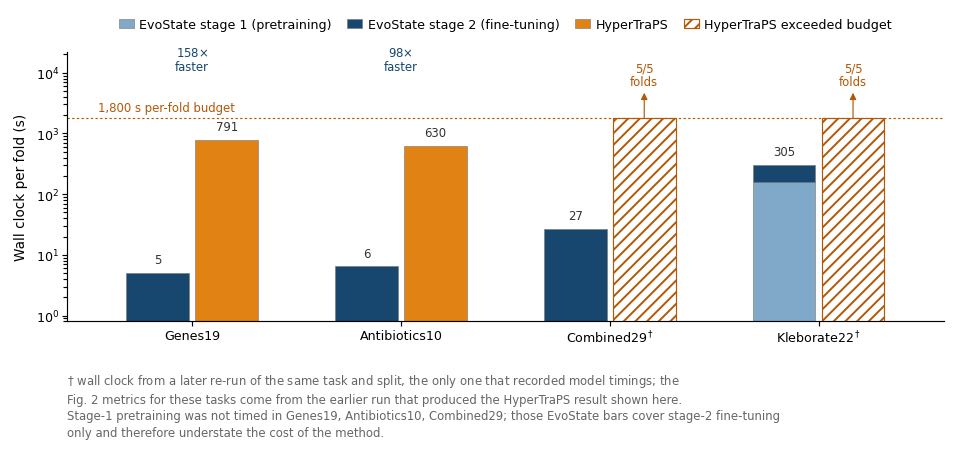

In [7]:
def draw_cost(ax, letter=None):
    """Supplementary figure: EvoState vs HyperTraPS wall clock, on the tasks where both were run.

    Only the four tasks on which HyperTraPS was attempted appear; the randomly initialised
    control is not part of this comparison and is omitted. The EvoState bar is stacked,
    stage 1 (state pretraining) below stage 2 (fine-tuning plus scoring), so the recorded-cost comparison includes stage 1 only when available.
    """
    order = []
    for t in TASKS:  # keep manuscript task order; drop tasks HyperTraPS never ran on
        task = t["task"]
        if df_task.query("task == @task").iloc[0]["ht_status"] != "not attempted":
            order.append(task)
    width = 0.30
    budget = float(np.nanmax(df_task["ht_timeout_sec"].astype(float)))
    ax.set_yscale("log")
    ax.set_ylim(0.8, budget * 12)

    def num(v):
        """True only for a real measurement; these columns are object dtype when a run
        recorded no timing at all, so np.isfinite alone raises."""
        try:
            return v is not None and np.isfinite(float(v))
        except (TypeError, ValueError):
            return False

    stage1_missing = []
    for i, task in enumerate(order):
        st = df_task.query("task == @task").iloc[0]
        x_ts, x_ht = i - width * 0.55, i + width * 0.55

        # --- EvoState: stage 1 + stage 2, stacked -----------------------------
        s2 = st["sec_per_fold_evostate"]
        s1 = st["sec_per_fold_pretrain_stage1"]
        if num(s2):
            if num(s1):
                ax.bar(x_ts, s1, width=width, color="#7fa8c9", edgecolor="#777777",
                       linewidth=0.3, zorder=2, label="_stage1")
                ax.bar(x_ts, s2, width=width, bottom=s1, color=COLOR["TS_pretrained"],
                       edgecolor="#777777", linewidth=0.3, zorder=2)
                total = s1 + s2
            else:
                stage1_missing.append(task)
                ax.bar(x_ts, s2, width=width, color=COLOR["TS_pretrained"],
                       edgecolor="#777777", linewidth=0.3, zorder=2)
                total = s2
            ax.text(x_ts, total * 1.30, f"{total:,.0f}", ha="center", va="bottom",
                    fontsize=SMALL, color="#333333")

        # --- HyperTraPS: measured, or the budget it never came back under -----
        ht = st["sec_per_fold_hypertraps"]
        if num(ht):
            ax.bar(x_ht, ht, width=width, color=COLOR["HT"], edgecolor="#777777",
                   linewidth=0.3, zorder=2)
            ax.text(x_ht, ht * 1.30, f"{ht:,.0f}", ha="center", va="bottom", fontsize=SMALL,
                    color="#333333")
        elif st["ht_status"] == "timed out":
            ax.bar(x_ht, budget, width=width, facecolor="none", edgecolor=ORANGE,
                   linewidth=0.6, hatch="////", zorder=2)
            ax.annotate("", xy=(x_ht, budget * 2.6), xytext=(x_ht, budget),
                        arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=0.6,
                                        shrinkA=0, shrinkB=0))
            ax.text(x_ht, budget * 3.1, f"{int(st['ht_folds_timed_out'])}/{int(st['n_folds'])}\nfolds",
                    ha="center", va="bottom", fontsize=SMALL, color=ORANGE, linespacing=1.1)

        if num(st["speedup_vs_hypertraps"]):
            ax.text(i, budget * 5.5, f"{st['speedup_vs_hypertraps']:.0f}$\\times$\nfaster",
                    ha="center", va="bottom", fontsize=SMALL, color=DARK, linespacing=1.1)

    ax.axhline(budget, color=ORANGE, lw=0.6, ls=(0, (2, 2)), zorder=1)
    ax.text(-0.45, budget * 1.15, f"{budget:,.0f} s per-fold budget", ha="left", va="bottom",
            fontsize=SMALL, color=ORANGE)
    ax.set_xticks(range(len(order)))
    flagged = {t: bool(df_task.query("task == @t").iloc[0]["runtime_from_other_run"]) for t in order}
    ax.set_xticklabels([f"{t}$^\\dagger$" if flagged[t] else t for t in order])
    ax.set_xlim(-0.6, len(order) - 0.4)
    ax.set_ylabel("Wall clock per fold (s)")
    style(ax)

    notes = []
    if any(flagged.values()):
        notes.append("$\\dagger$ wall clock from a later re-run of the same task and split, the only "
                     "one that recorded model timings; the Fig. 2 metrics for these tasks come from "
                     "the earlier run that produced the HyperTraPS result shown here.")
    if stage1_missing:
        notes.append("Stage-1 pretraining was not timed in " + ", ".join(stage1_missing) +
                     "; those EvoState bars cover stage-2 fine-tuning only and therefore "
                     "understate the cost of the method.")
    if notes:
        ax.text(0.0, -0.19, "\n".join(textwrap.fill(n, 118) for n in notes),
                transform=ax.transAxes, ha="left", va="top", fontsize=SMALL, color="#666666",
                linespacing=1.35)
    if letter:
        panel_letter(ax, letter, dx=-46)

    any_stage1 = len(stage1_missing) < len(order)
    handles = []
    if any_stage1:  # no legend key without a bar to match it
        handles.append(Patch(facecolor="#7fa8c9", edgecolor="#777777", linewidth=0.3,
                             label="EvoState stage 1 (pretraining)"))
    handles += [Patch(facecolor=COLOR["TS_pretrained"], edgecolor="#777777", linewidth=0.3,
                      label="EvoState stage 2 (fine-tuning)" if any_stage1 else "EvoState"),
                Patch(facecolor=COLOR["HT"], edgecolor="#777777", linewidth=0.3, label="HyperTraPS"),
                Patch(facecolor="none", edgecolor=ORANGE, hatch="////", linewidth=0.6,
                      label="HyperTraPS exceeded budget")]
    ax.legend(handles=handles, ncol=len(handles), frameon=False, loc="upper center",
              bbox_to_anchor=(0.5, 1.17), columnspacing=1.2,
              handlelength=1.2, handletextpad=0.45, fontsize=SMALL + 0.5)


figS = plt.figure(figsize=(7.20, 3.40))
draw_cost(figS.add_axes([0.108, 0.300, 0.870, 0.565]))

figS.savefig(OUT / "supplementary_fig_compute_cost.pdf", bbox_inches="tight")
figS.savefig(OUT / "supplementary_fig_compute_cost.png", bbox_inches="tight", dpi=300)
print("Supplementary figure (EvoState vs HyperTraPS cost) written")
plt.show()


## 6. Tables and quotable numbers

In [8]:
wide = (df_method[df_method["available"]]
        .pivot_table(index=["dataset", "task"], columns="method", values=[m[0] for m in METRICS])
        .reindex(columns=pd.MultiIndex.from_product([[m[0] for m in METRICS], METHOD_KEYS])))
wide.columns = [f"{metric}__{method}" for metric, method in wide.columns]
tab = (df_task.set_index(["dataset", "task"])[[
            "L", "n_transitions", "n_groups", "n_folds", "mean_n_candidates", "frac_multi_gain",
            "delta_vs_prevalence", "p_vs_prevalence", "q_vs_prevalence",
            "delta_vs_random", "p_vs_random", "q_vs_random",
            "delta_vs_hypertraps", "p_vs_hypertraps", "q_vs_hypertraps", "ht_status"]]
       .join(wide))
tab = tab.loc[[(t["dataset"], t["task"]) for t in TASKS]]
tab.to_csv(OUT / "table1_conditional_transition.csv")

cost_tab = df_task.set_index(["dataset", "task"])[[
    "L", "sec_per_fold_random_init", "sec_per_fold_pretrain_stage1", "sec_per_fold_evostate",
    "sec_per_fold_evostate_total", "evostate_total_includes_stage1", "sec_per_fold_hypertraps",
    "speedup_vs_hypertraps", "finetune_speedup", "delta_vs_hypertraps", "p_vs_hypertraps",
    "q_vs_hypertraps", "ht_status", "ht_folds_timed_out", "ht_timeout_sec",
    "runtime_source", "runtime_run", "runtime_from_other_run"]]
cost_tab.to_csv(OUT / "table2_compute_cost.csv")

delta_cols = ["dataset", "task"]
for mkey, _, _ in DELTA_METRICS:
    delta_cols += [f"delta_{mkey}", f"fold_ci95_{mkey}", f"ci_excludes_zero_{mkey}",
                   f"n_folds_positive_{mkey}"]
df_delta[delta_cols].to_csv(OUT / "tableS_metric_deltas.csv", index=False)

(df_method[df_method["available"]]
 .set_index(["dataset", "task", "method"])[["auc_all", "event_mrr", "rec3", "rec5", "multi_top1"]]
 .to_csv(OUT / "tableS_event_level_metrics.csv"))

print("written:", sorted(p.name for p in OUT.iterdir() if p.is_file()))
cost_tab.round(2)

written: ['figure2.pdf', 'figure2.png', 'figure2_source_data_folds.csv', 'figure2_source_data_methods.csv', 'figure2_source_data_pretraining_delta.csv', 'figure2_source_data_tasks.csv', 'historical_tests_audit.csv', 'supplementary_fig_compute_cost.pdf', 'supplementary_fig_compute_cost.png', 'table1_conditional_transition.csv', 'table2_compute_cost.csv', 'tableS_event_level_metrics.csv', 'tableS_metric_deltas.csv']


L  sec_per_fold_random_init  \
dataset         task                                            
M. tuberculosis Genes19          19                      6.45   
                Antibiotics10    10                      7.17   
                Combined29       29                     26.44   
K. pneumoniae   Kleborate22      22                    121.22   
E. coli         MEC             858                    942.27   
                NIT             320                    168.17   
                TMP            1081                  92268.78   

                               sec_per_fold_pretrain_stage1  \
dataset         task                                          
M. tuberculosis Genes19                                 NaN   
                Antibiotics10                           NaN   
                Combined29                              NaN   
K. pneumoniae   Kleborate22                          159.39   
E. coli         MEC                                     NaN   
                NIT                                     NaN   
                TMP                                     NaN   

                               sec_per_fold_evostate  \
dataset         task                                   
M. tuberculosis Genes19                         5.01   
                Antibiotics10                   6.42   
                Combined29                     26.62   
K. pneumoniae   Kleborate22                   145.14   
E. coli         MEC                           254.93   
                NIT                            49.79   
                TMP                         26405.65   

                               sec_per_fold_evostate_total  \
dataset         task                                         
M. tuberculosis Genes19                               5.01   
                Antibiotics10                         6.42   
                Combined29                           26.62   
K. pneumoniae   Kleborate22                         304.53   
E. coli         MEC                                 254.93   
                NIT                                  49.79   
                TMP                               26405.65   

                               evostate_total_includes_stage1  \
dataset         task                                            
M. tuberculosis Genes19                                 False   
                Antibiotics10                           False   
                Combined29                              False   
K. pneumoniae   Kleborate22                              True   
E. coli         MEC                                     False   
                NIT                                     False   
                TMP                                     False   

                               sec_per_fold_hypertraps  speedup_vs_hypertraps  \
dataset         task                                                            
M. tuberculosis Genes19                         791.07                 157.99   
                Antibiotics10                   629.96                  98.06   
                Combined29                         NaN                    NaN   
K. pneumoniae   Kleborate22                        NaN                    NaN   
E. coli         MEC                                NaN                    NaN   
                NIT                                NaN                    NaN   
                TMP                                NaN                    NaN   

                               finetune_speedup  delta_vs_hypertraps  \
dataset         task                                                   
M. tuberculosis Genes19                    1.29                -0.04   
                Antibiotics10              1.12                -0.02   
                Combined29                 0.99                  NaN   
K. pneumoniae   Kleborate22                0.84                  NaN   
E. coli         MEC                        3.70                  NaN

In [9]:
for t in TASKS:
    ds, task = t["dataset"], t["task"]
    d = df_delta.query("dataset == @ds and task == @task").iloc[0]
    st = df_task.query("dataset == @ds and task == @task").iloc[0]
    b1 = df_method.query("dataset == @ds and task == @task and method == 'B1_prevalence'").iloc[0]
    flags = "".join("*" if d[f"ci_excludes_zero_{m}"] else "." for m, _, _ in DELTA_METRICS)
    print(f"{task:<14} L={int(st['L']):>5} n={int(st['n_transitions']):>5}/{int(st['n_groups']):>4} "
          f"|C|~{st['mean_n_candidates']:>6.0f}  "
          f"logL {d['mean_logl_rnd']:+.3f}->{d['mean_logl_pre']:+.3f} "
          f"(d={d['delta_mean_logl']:+.3f})  "
          f"dTop1={d['delta_top1']:+.3f} dTop5={d['delta_top5']:+.3f} "
          f"dMRR={d['delta_mrr']:+.3f} dAUC={d['delta_auc']:+.3f}  CI-excl-0[{flags}]  "
          f"[gain-frequency AUC {b1['auc']:.3f}]")

print()
for (ds, task), r in cost_tab.iterrows():
    if np.isfinite(r["speedup_vs_hypertraps"]):
        print(f"{task:<14} HyperTraPS {r['sec_per_fold_hypertraps']:>8.1f} s/fold vs EvoState "
              f"{r['sec_per_fold_evostate']:>6.1f} s/fold -> {r['speedup_vs_hypertraps']:.0f}x; "
              f"logL difference {r['delta_vs_hypertraps']:+.3f}")
    elif r["ht_status"] == "timed out":
        print(f"{task:<14} HyperTraPS exceeded configured budget: {int(r['ht_folds_timed_out'])}/5 folds exceeded "
              f"{r['ht_timeout_sec']:.0f} s (run.log: TimeoutExpired); timing provenance is listed in runtime_scope_audit.csv")
    else:
        print(f"{task:<14} HyperTraPS {r['ht_status']}; EvoState {r['sec_per_fold_evostate']:.1f} s/fold, "
              f"fine-tuning {r['finetune_speedup']:.1f}x faster than the control")

Genes19        L=   19 n=  264/  44 |C|~    13  logL -1.971->-1.979 (d=-0.008)  dTop1=+0.006 dTop5=-0.004 dMRR=+0.003 dAUC=-0.004  CI-excl-0[....]  [gain-frequency AUC 0.720]
Antibiotics10  L=   10 n=  427/  58 |C|~     7  logL -1.353->-1.353 (d=-0.001)  dTop1=-0.022 dTop5=+0.005 dMRR=-0.007 dAUC=+0.001  CI-excl-0[....]  [gain-frequency AUC 0.744]
Combined29     L=   29 n=  485/  58 |C|~    20  logL -2.125->-2.100 (d=+0.025)  dTop1=-0.014 dTop5=+0.009 dMRR=+0.002 dAUC=+0.006  CI-excl-0[....]  [gain-frequency AUC 0.809]
Kleborate22    L=   22 n= 9026/ 980 |C|~    16  logL -1.746->-1.731 (d=+0.015)  dTop1=-0.003 dTop5=+0.011 dMRR=+0.001 dAUC=+0.002  CI-excl-0[.*..]  [gain-frequency AUC 0.805]
MEC            L=  858 n= 2258/  33 |C|~   721  logL -5.777->-3.036 (d=+2.741)  dTop1=+0.274 dTop5=+0.573 dMRR=+0.386 dAUC=+0.187  CI-excl-0[****]  [gain-frequency AUC 0.432]
NIT            L=  320 n= 1819/  36 |C|~   290  logL -2.465->-1.348 (d=+1.117)  dTop1=+0.128 dTop5=+0.120 dMRR=+0.122 dAUC=+0

## Interpretation and reporting boundaries

Across all seven tasks, EvoState improves held-out likelihood relative to the gain-frequency baseline. Additional pretraining gains are largest in MEC, NIT and TMP and directionally consistent across the reported ranking metrics. Lower-dimensional tasks have small and metric-dependent increments. This does not identify dimensionality as the cause.

Figure intervals and per-fold markers describe variability across overlapping CV folds; they are not independent phylogenetic confidence intervals. Legacy bootstrap tests are not reused for significance claims in this revision.

Run-specific mean_logl is retained without claiming identical single-gain/multi-gain weighting across tasks. Event-level coverage is documented in the audit; missing outputs must not be treated as zero. Kp multi-event ranking does not uniformly favor pretraining.

Recorded training/evaluation costs are not a standardized end-to-end benchmark. The cost provenance table identifies alternate runs and whether stage-1 is recorded. HyperTraPS completion on a subset of tasks permits only a subset comparison.

Recommended Results title: **EvoState predicts conditional resistance acquisition with task-dependent benefits from pretraining.**

Figure caption: Absolute likelihood and ranking performance and pretraining contrasts across seven tasks. Error bars and fold points summarize descriptive cross-validation variability; no significance stars are assigned. Cost panels show recorded computational costs under the evaluated configurations; stage-1 inclusion, alternate timing runs and unavailable HyperTraPS results are specified in accompanying source tables. Endpoint-derived targets are conditional prediction benchmarks, not direct measurements of acquisition chronology.

In [10]:
import hashlib
audit_rows = []
input_hashes = {}
for task in TASKS:
    path = task['run'] / 'eval_summary.json'
    summary = load_json(path)
    input_hashes[str(path)] = hashlib.sha256(path.read_bytes()).hexdigest()
    profile = summary.get('transition_profile', {})
    for method, metrics in summary['overall'].items():
        for metric in sorted(set(['mean_logl', 'top1', 'top3', 'top5', 'mrr', 'auc', 'multi_top1', 'event_auc', 'event_top1', 'event_top3', 'event_top5']) | {key for key in metrics if key.startswith(('event_', 'multi_', 'single_'))}):
            value = metrics.get(metric)
            audit_rows.append({'dataset': task['dataset'], 'task': task['task'], 'method': method, 'metric': metric, 'value': value, 'status': 'reported' if value is not None else 'not reported in source summary', 'transition_profile': json.dumps(profile)})
pd.DataFrame(audit_rows).to_csv(OUT / 'event_metric_availability_audit.csv', index=False)
runtime_cols = ['dataset', 'task', 'runtime_source', 'runtime_run', 'runtime_from_other_run', 'evostate_total_includes_stage1', 'ht_status']
df_task[runtime_cols].to_csv(OUT / 'runtime_scope_audit.csv', index=False)
assert len(df_task) == 7
assert not df_task[legacy_cols].notna().any().any()
(OUT / 'revision_manifest.json').write_text(json.dumps({'inputs_sha256': input_hashes, 'training_performed': False, 'historical_tests': 'retained separately; not used for inference', 'source_notebook': 'figure2_conditional_transition.ipynb'}, indent=2))
print('Revision complete:', OUT)

Revision complete: /apdcephfs_qy3/share_2932069/ziyiyang/1-antibiotic_resistance/EvoAMR/evoamr/evostate/results/rendered/manuscript/figure2
